## Import & Path

In [14]:
# ============================================================
# CELL 1 — IMPORT LIBRARY & KONFIGURASI PATH
# ============================================================

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

from scipy.stats import skew, kurtosis, jarque_bera, norm

mpl.rcParams['font.family'] = 'Times New Roman'
mpl.rcParams['figure.dpi'] = 200
plt.rcParams['figure.dpi'] = 200

ROOT_DIR = Path('../../')

RAW_DIR = ROOT_DIR / '03_dataset' / 'raw'
PROCESSED_DIR = ROOT_DIR / '03_dataset' / 'processed'
OUTPUT_DIR = ROOT_DIR / '06_dokumen_tesis'

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

URUT_EMITEN = ['ADRO', 'ADMR', 'ITMG', 'PTBA', 'MEDC', 'AKRA', 'PGAS']

WARNA = '#1F4E79'                                   # satu warna untuk semua emiten (biru tua)
colors = {kode: WARNA for kode in URUT_EMITEN}


## Load data & hitung log return

In [15]:
# ============================================================
# CELL 2 — LOAD DATA & HITUNG LOG RETURN (FIXED)
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

# ===== PATH FIX =====
RAW_DIR = Path(r"E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\raw")

INPUT_FILE = RAW_DIR / "harga_saham_raw.csv"

# ===== CEK FILE =====
assert INPUT_FILE.exists(), f"File tidak ditemukan:\n{INPUT_FILE}"

# ===== LOAD DATA =====
df = pd.read_csv(INPUT_FILE, encoding='utf-8-sig')

# ===== CLEAN COLUMN =====
df.columns = df.columns.str.strip()

# ===== CEK KOLOM WAJIB =====
required_cols = ['Date', 'Kode_Emiten', 'Adj Close']
missing_cols = [c for c in required_cols if c not in df.columns]

if missing_cols:
    # Sesuaikan nama kolom dataset dengan nama yang digunakan notebook
    df.rename(columns={
        'Emiten': 'Kode_Emiten',
        'Adj_Close': 'Adj Close'
    }, inplace=True)

    missing_cols = [c for c in required_cols if c not in df.columns]
    if missing_cols:
        raise ValueError(
            f"Kolom hilang di dataset: {missing_cols}\n"
            f"Kolom tersedia: {df.columns.tolist()}"
        )

# ===== FORMAT DATE =====
df['Date'] = pd.to_datetime(df['Date'])

# ===== SORT =====
df = df.sort_values(['Kode_Emiten', 'Date']).reset_index(drop=True)

# ===== LOG RETURN =====
price_col = 'Adj Close'

df['Log_Return'] = (
    df.groupby('Kode_Emiten')[price_col]
      .transform(lambda x: np.log(x / x.shift(1)))
)

display(df.head())

# ===== CEK CAKUPAN DATA (BARU) =====
# Pastikan periode penelitian Januari 2022 – Juni 2026 dan hitung hari bervolume 0
AWAL, AKHIR = '2022-01-01', '2026-06-30'
df = df[(df['Date'] >= AWAL) & (df['Date'] <= AKHIR)].reset_index(drop=True)

cek = df.groupby('Kode_Emiten').agg(
    Mulai=('Date', 'min'), Akhir=('Date', 'max'), Hari=('Date', 'count'),
    Volume_0=('Volume', lambda v: int((v == 0).sum())),
    Return_NaN=('Log_Return', lambda r: int(r.isna().sum()))).reindex(URUT_EMITEN)
print('Cakupan data per emiten:')
display(cek)


,Date,Open,High,Low,Close,Adj Close,Volume,Kode_Emiten,Log_Return
0,2022-01-03,135.0,135.0,135.0,135.0,125.224686,34289600,ADMR,NaN
1,2022-01-04,182.0,182.0,182.0,182.0,168.821442,22170900,ADMR,0.298732
2,2022-01-05,220.0,244.0,220.0,244.0,226.332031,43203600,ADMR,0.293161
3,2022-01-06,304.0,304.0,304.0,304.0,281.987457,52097500,ADMR,0.219860
4,2022-01-07,380.0,380.0,380.0,380.0,352.484314,19248600,ADMR,0.223144


Cakupan data per emiten:


,Mulai,Akhir,Hari,Volume_0,Return_NaN
Kode_Emiten,,,,,
ADRO,2022-01-03,2026-06-30,1074,4,0
ADMR,2022-01-03,2026-06-30,1074,12,1
ITMG,2022-01-03,2026-06-30,1074,5,0
PTBA,2022-01-03,2026-06-30,1074,4,0
MEDC,2022-01-03,2026-06-30,1074,4,0
AKRA,2022-01-03,2026-06-30,1074,5,0
PGAS,2022-01-03,2026-06-30,1074,4,0


## Statistik deskriptif log return

In [16]:
# ============================================================
# CELL 3 — STATISTIK DESKRIPTIF LOG RETURN (Tabel 4.4)
# ============================================================
# Skewness dan kurtosis memakai pandas (koreksi bias sampel) agar sama dengan Tabel 4.4.
# Kurtosis yang dihasilkan adalah EXCESS KURTOSIS (distribusi normal = 0).

summary = []
for kode in URUT_EMITEN:
    data = df.loc[df['Kode_Emiten'] == kode, 'Log_Return'].dropna()
    summary.append({
        'Emiten': kode,
        'N': len(data),
        'Mean': data.mean(),
        'Std Dev': data.std(),
        'Min': data.min(),
        'Maks': data.max(),
        'Skewness': data.skew(),
        'Excess Kurtosis': data.kurt(),
    })

desc = pd.DataFrame(summary).round(6)
display(desc)

desc.to_csv(OUTPUT_DIR / 'Tabel_4_4_statistik_log_return.csv', index=False, encoding='utf-8-sig')

# Tanggal return ekstrem (untuk dijelaskan di narasi, mis. ex-dividend atau aksi korporasi)
ekstrem = []
for kode in URUT_EMITEN:
    sub = df[df['Kode_Emiten'] == kode].dropna(subset=['Log_Return'])
    i_min, i_max = sub['Log_Return'].idxmin(), sub['Log_Return'].idxmax()
    ekstrem.append({'Emiten': kode,
                    'Tanggal Min': sub.loc[i_min, 'Date'].date(), 'Return Min': round(sub.loc[i_min, 'Log_Return'], 5),
                    'Tanggal Maks': sub.loc[i_max, 'Date'].date(), 'Return Maks': round(sub.loc[i_max, 'Log_Return'], 5)})
print('Tanggal return ekstrem:')
display(pd.DataFrame(ekstrem))


,Emiten,N,Mean,Std Dev,Min,Maks,Skewness,Excess Kurtosis
0,ADRO,1074,0.001014,0.027339,-0.282863,0.177196,-0.269746,14.601248
1,ADMR,1073,0.002213,0.041446,-0.130362,0.298732,1.827833,9.162397
2,ITMG,1074,0.000780,0.019896,-0.072238,0.117899,0.367768,3.842257
3,PTBA,1074,0.000609,0.020943,-0.161586,0.189605,0.561956,11.234172
4,MEDC,1074,0.000920,0.031749,-0.160623,0.186984,0.462724,3.297272
5,AKRA,1074,0.000656,0.025390,-0.121214,0.200671,0.467067,5.060653
6,PGAS,1074,0.000414,0.020418,-0.145050,0.107631,-0.168116,4.396422


Tanggal return ekstrem:


,Emiten,Tanggal Min,Return Min,Tanggal Maks,Return Maks
0,ADRO,2024-11-29,-0.28286,2024-11-28,0.17720
1,ADMR,2025-04-08,-0.13036,2022-01-04,0.29873
2,ITMG,2023-04-12,-0.07224,2022-02-24,0.11790
3,PTBA,2023-06-27,-0.16159,2023-06-26,0.18961
4,MEDC,2026-05-21,-0.16062,2023-09-01,0.18698
5,AKRA,2025-04-08,-0.12121,2025-04-10,0.20067
6,PGAS,2026-03-09,-0.14505,2024-04-30,0.10763


## Time series log return

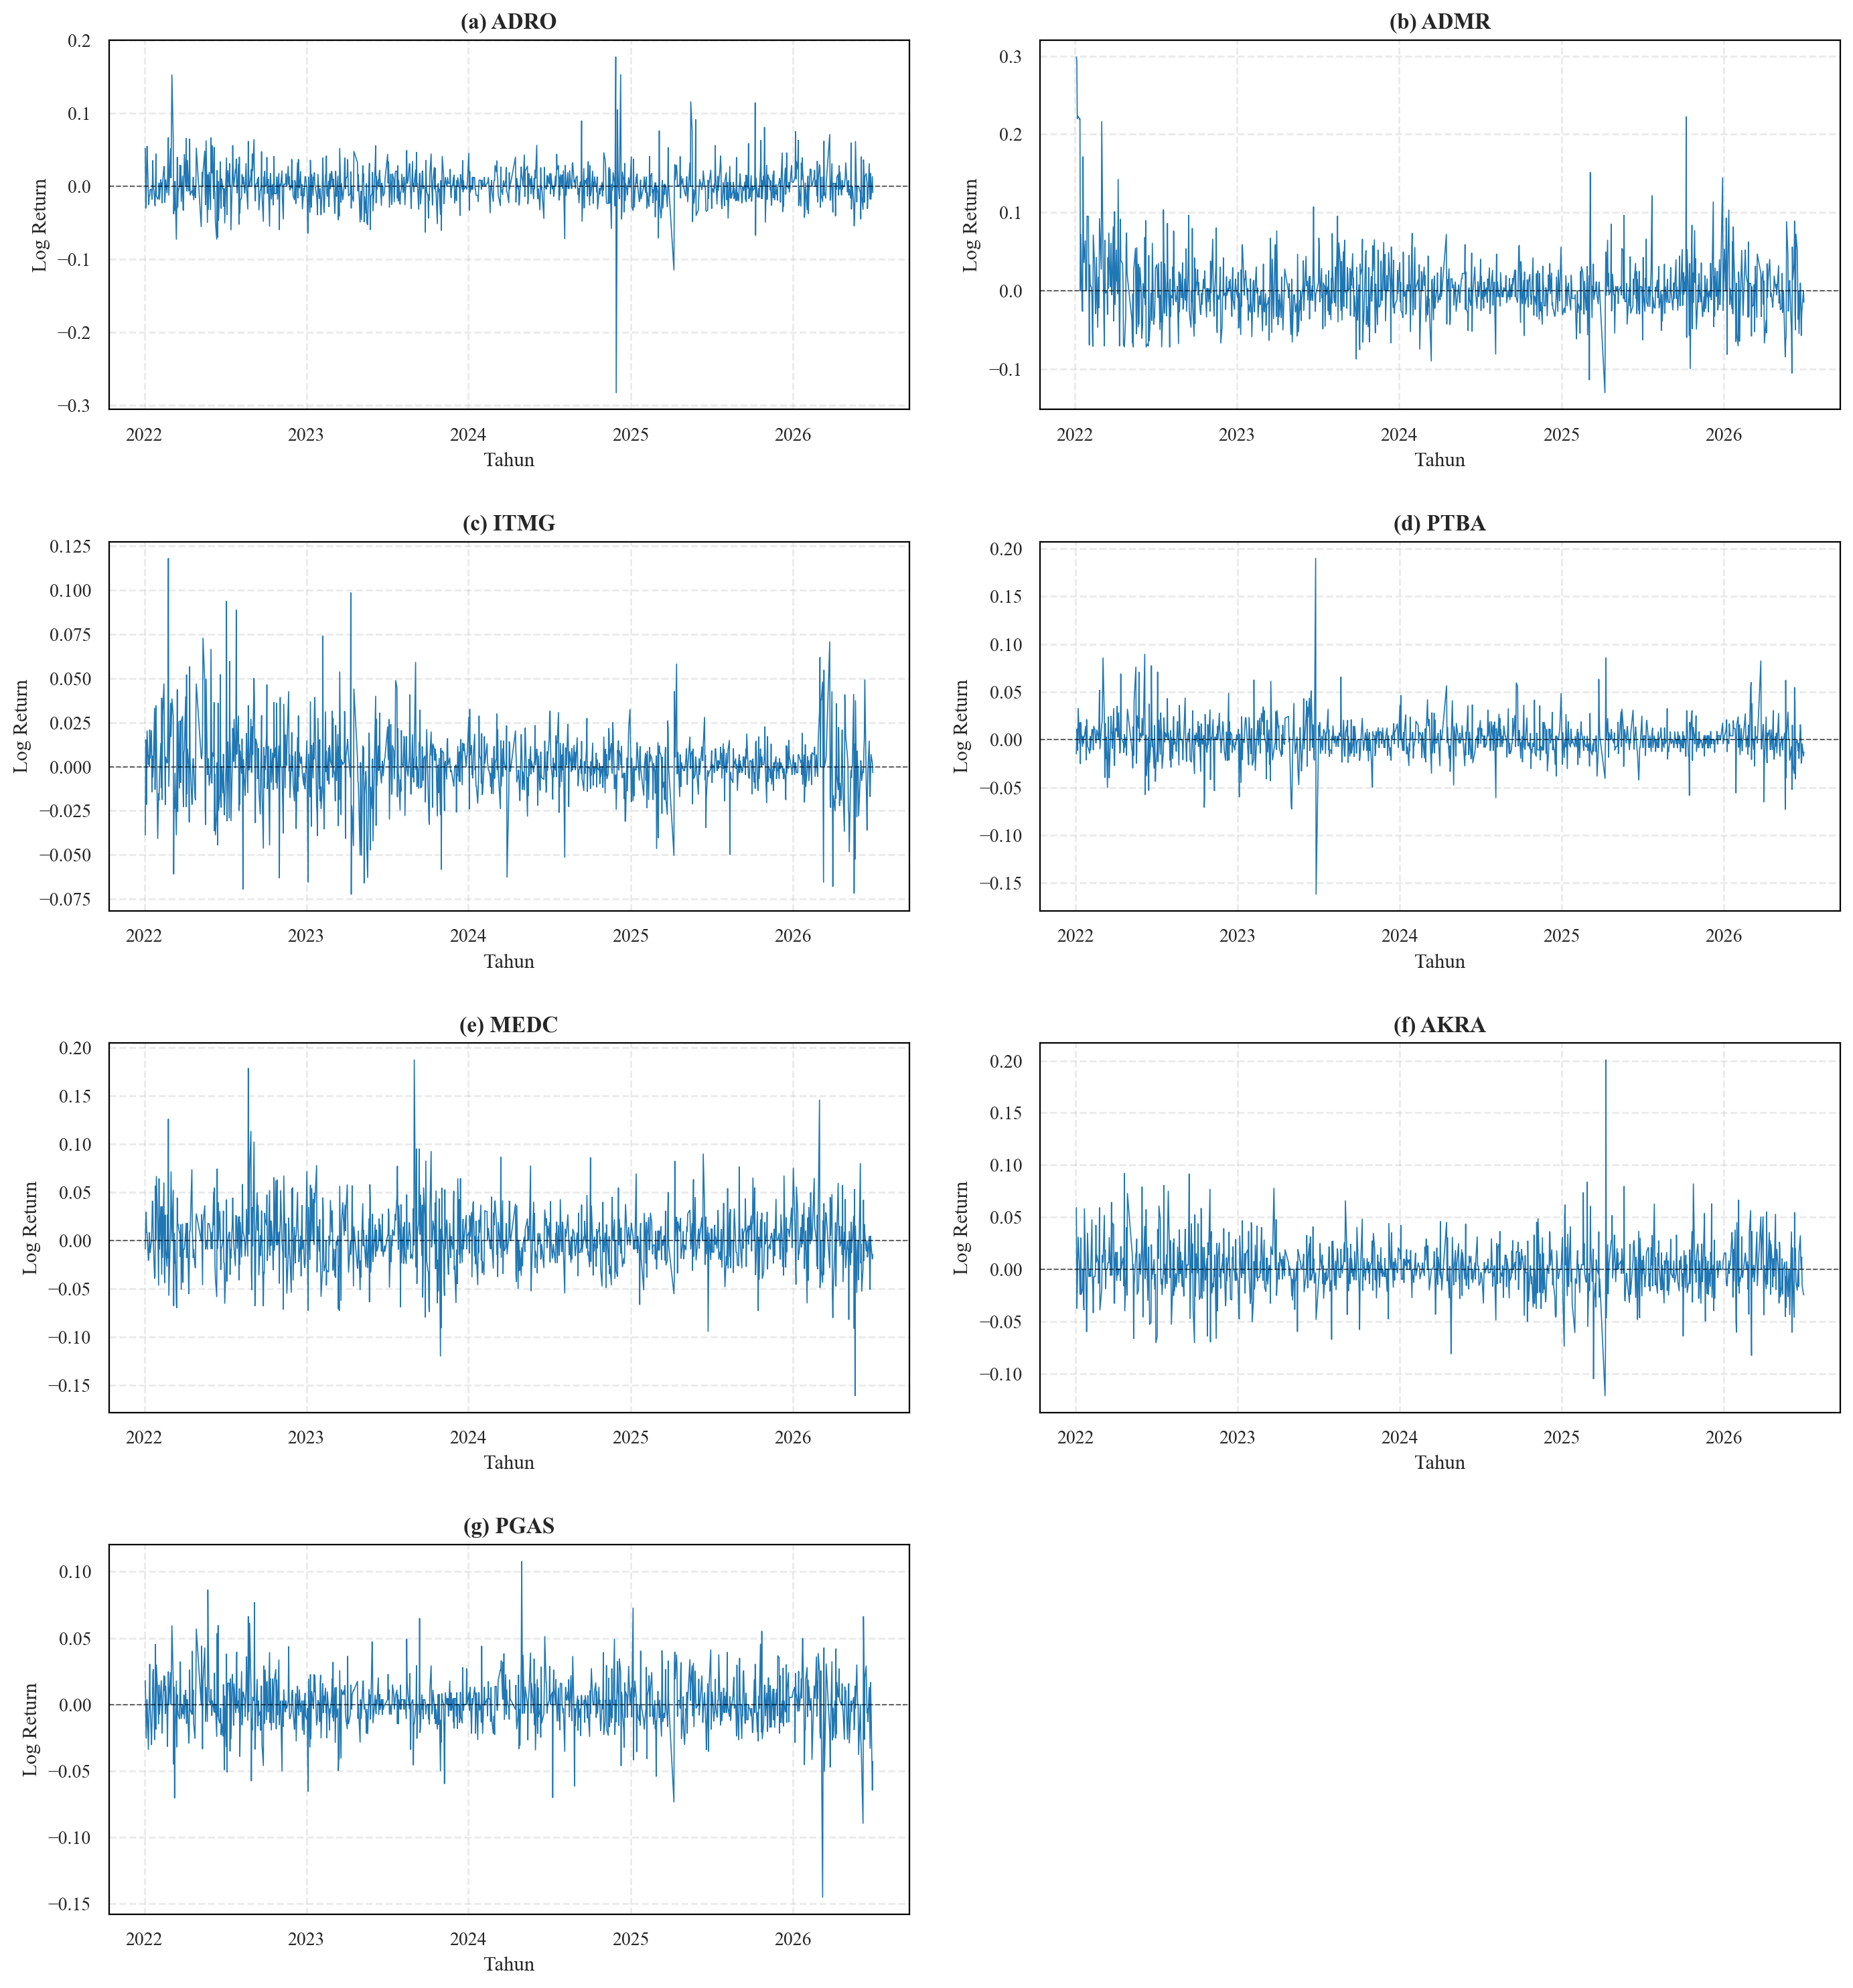

In [22]:
# ============================================================
# CELL 4 — TIME SERIES LOG RETURN (Gambar 4.2)
# ============================================================
import matplotlib.dates as mdates

WARNA = '#1f77b4'                              # satu warna untuk semua panel
HURUF = 'abcdefghijklmnopqrstuvwxyz'

fig, axes = plt.subplots(4, 2, figsize=(14, 15))
axes = axes.flatten()

for i, kode in enumerate(URUT_EMITEN):
    ax = axes[i]
    sub = df[df['Kode_Emiten'] == kode].dropna(subset=['Log_Return'])

    ax.plot(sub['Date'], sub['Log_Return'], color=WARNA, linewidth=0.6)
    ax.axhline(0, color='black', linestyle='--', linewidth=0.7, alpha=0.6)

    ax.set_title(f'({HURUF[i]}) {kode}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Tahun', fontsize=11)
    ax.set_ylabel('Log Return', fontsize=11)

    ax.xaxis.set_major_locator(mdates.YearLocator())          # satu label per tahun
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax.tick_params(axis='both', labelsize=10)

    ax.grid(True, linestyle='--', alpha=0.4)
    for s in ax.spines.values():                               # bingkai penuh
        s.set_visible(True); s.set_color('black'); s.set_linewidth(0.8)

for j in range(len(URUT_EMITEN), len(axes)):                   # hapus panel kosong ke-8
    fig.delaxes(axes[j])

plt.tight_layout(h_pad=2.0, w_pad=2.0)
plt.savefig(OUTPUT_DIR / 'Gambar_4_2_time_series_log_return.png',
            dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

## Histogram log return

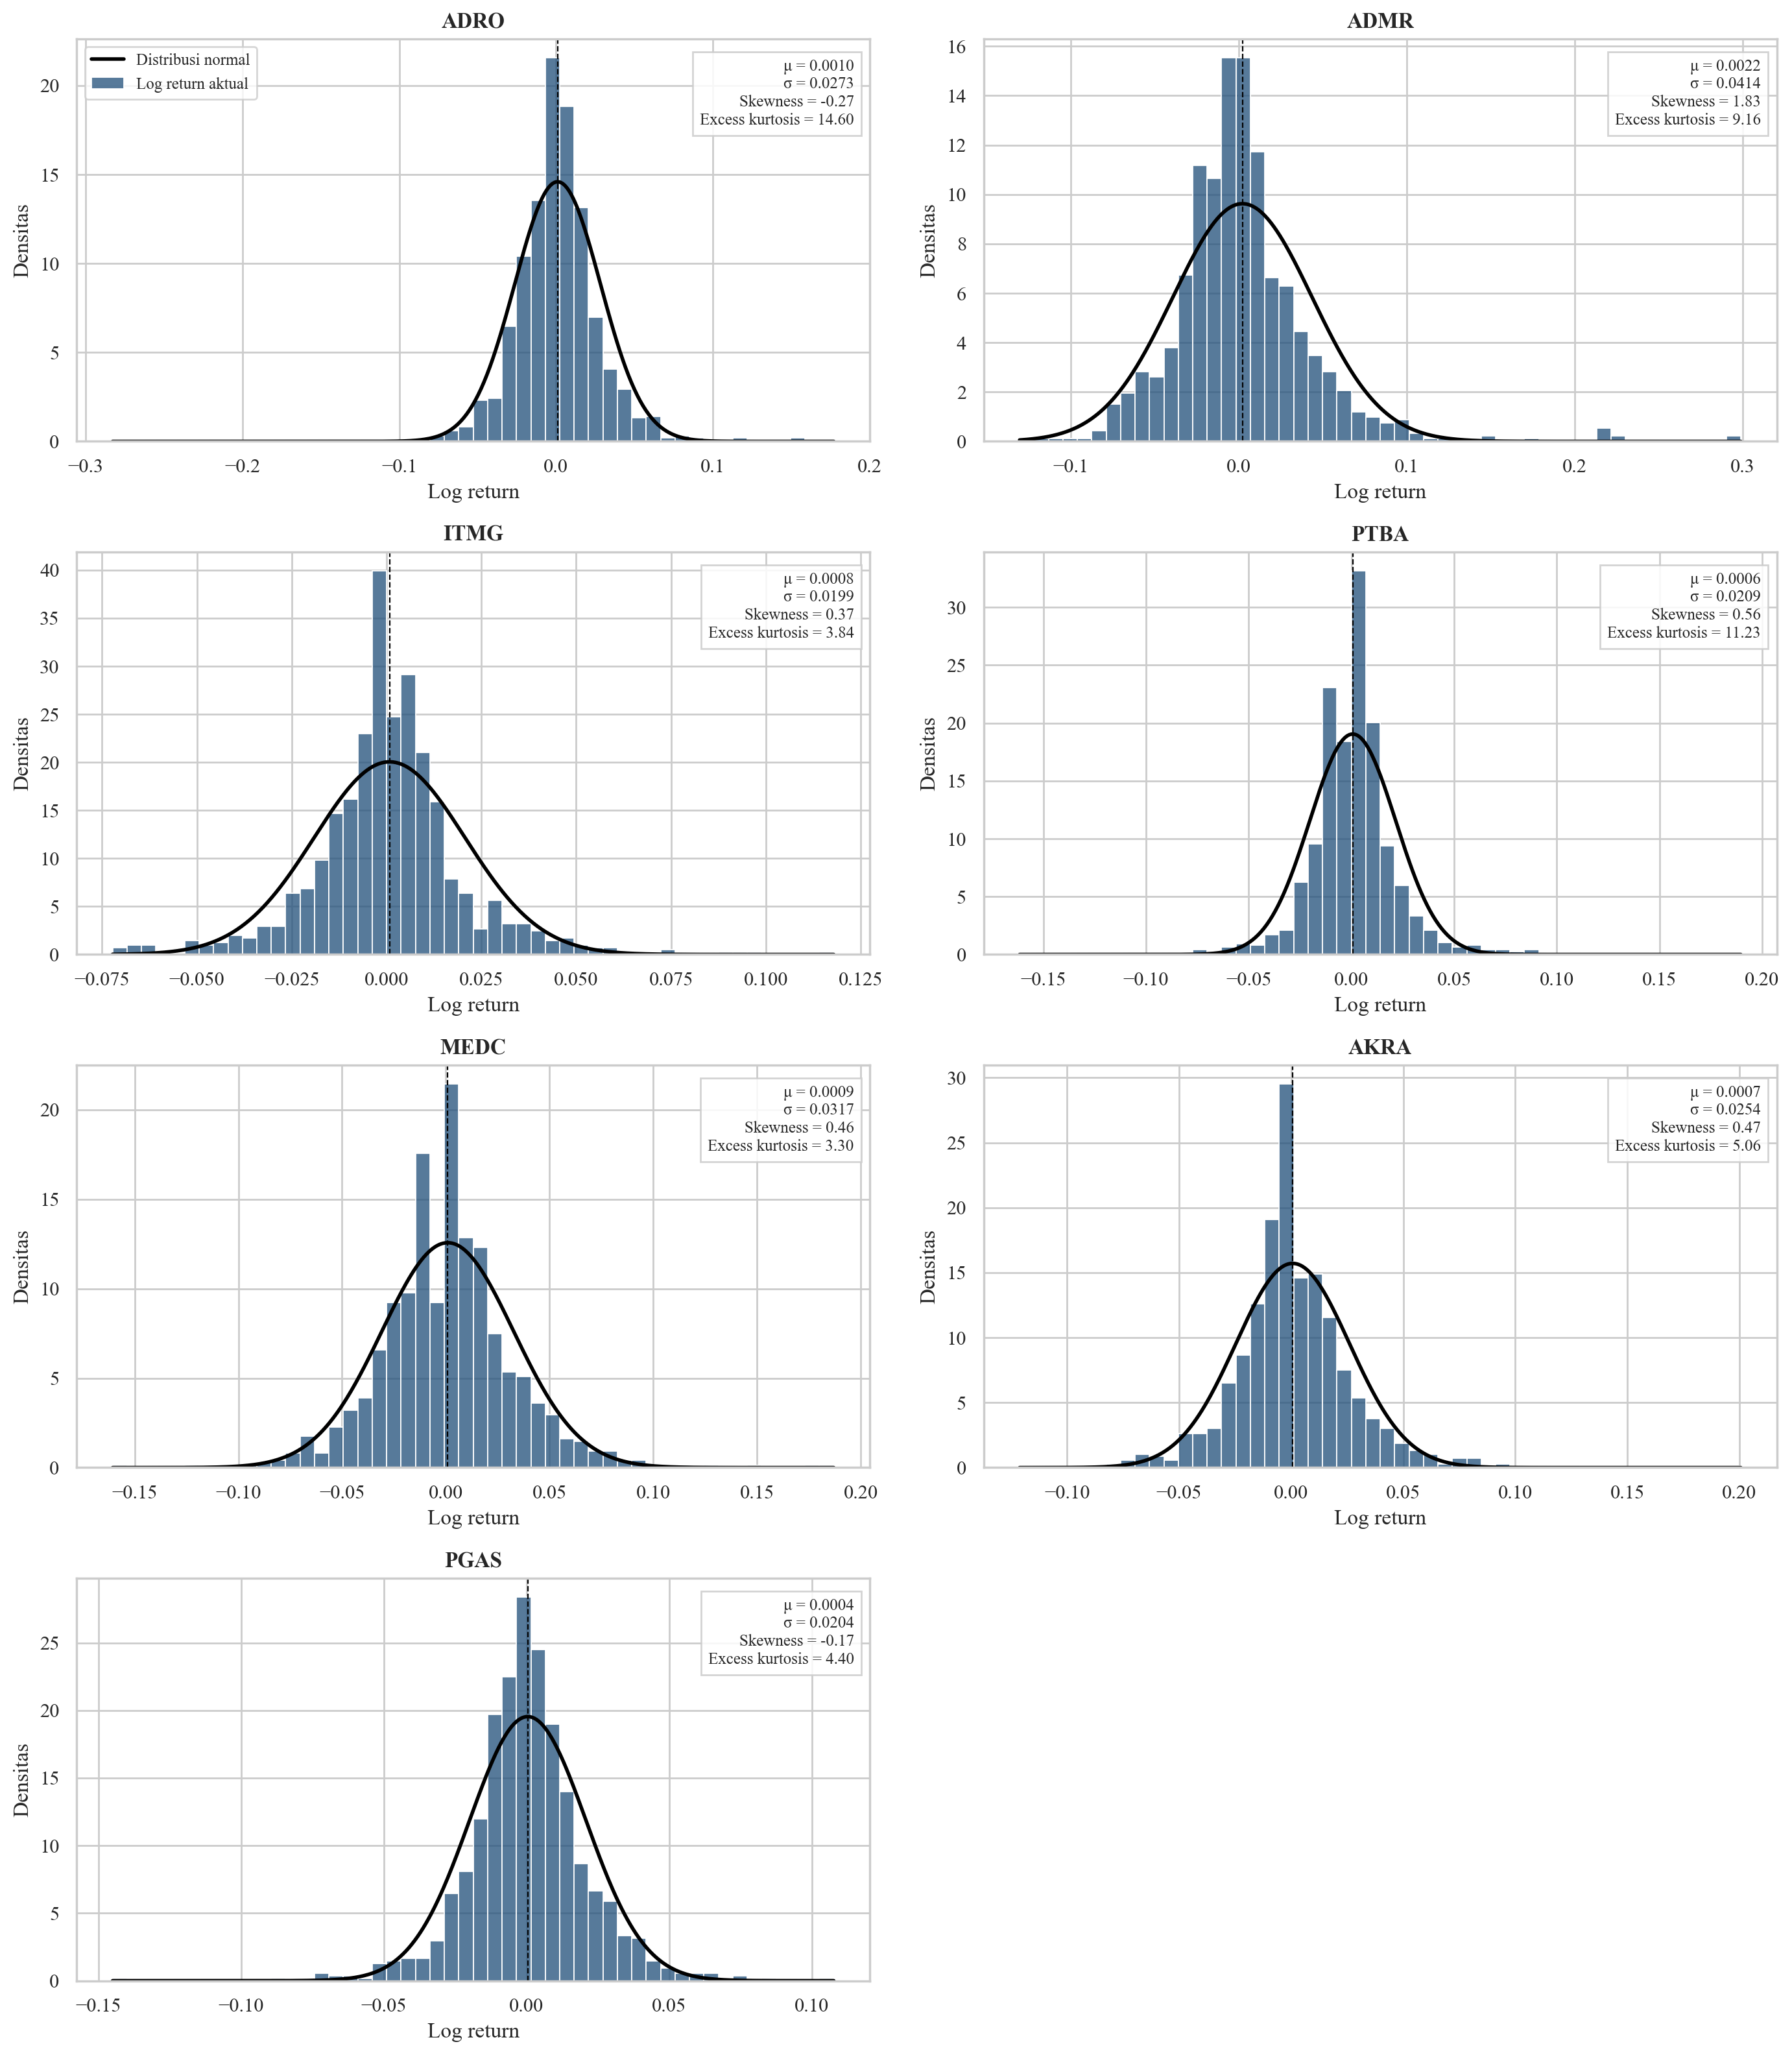

In [18]:
# ============================================================
# CELL 5 — HISTOGRAM LOG RETURN + KURVA NORMAL (Gambar 4.3)
# ============================================================

sns.set_theme(style="whitegrid", font='Times New Roman')

fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()
for i, kode in enumerate(emitens):
    ax = axes[i]
    data = df.loc[df['Kode_Emiten'] == kode, 'Log_Return'].dropna()
    mu, sigma = data.mean(), data.std()

    sns.histplot(data, bins=50, stat='density', color=colors[kode],
                 edgecolor='white', alpha=0.75, ax=ax, label='Log return aktual')
    x = np.linspace(data.min(), data.max(), 500)
    ax.plot(x, norm.pdf(x, mu, sigma), linewidth=2, color='black', label='Distribusi normal')
    ax.axvline(mu, linestyle='--', color='black', linewidth=0.8)

    ax.set_title(kode, fontweight='bold')
    ax.set_xlabel('Log return'); ax.set_ylabel('Densitas')
    ax.text(0.98, 0.95,
            f'μ = {mu:.4f}\nσ = {sigma:.4f}\nSkewness = {data.skew():.2f}\nExcess kurtosis = {data.kurt():.2f}',
            transform=ax.transAxes, ha='right', va='top', fontsize=9,
            bbox=dict(facecolor='white', alpha=0.85, edgecolor='#cccccc'))
    if i == 0:
        ax.legend(loc='upper left', fontsize=9)
for j in range(len(emitens), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'Gambar_4_3_histogram_log_return.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()


## Boxplot log return (opsional)

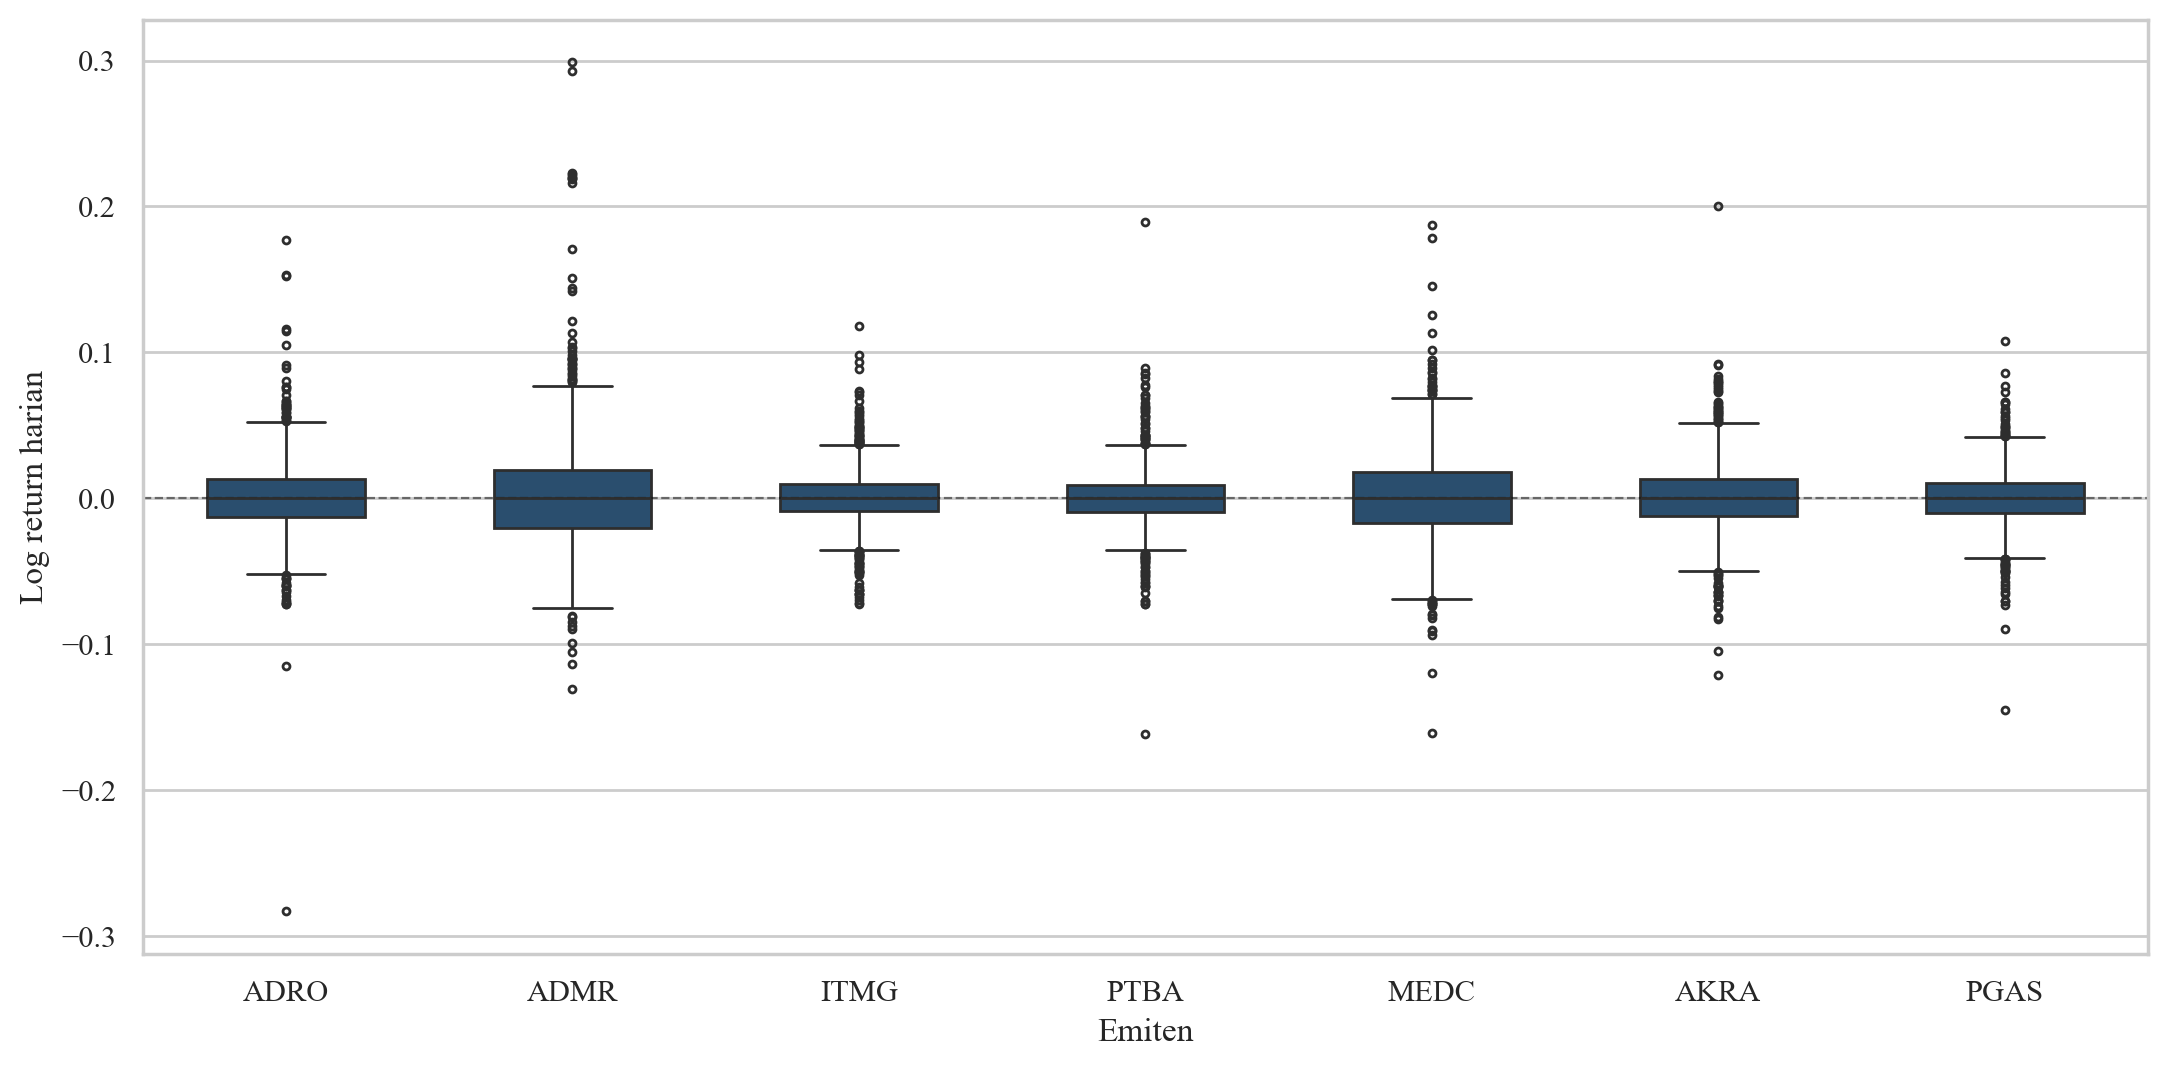

In [19]:
# ============================================================
# CELL 5B — BOXPLOT LOG RETURN KETUJUH EMITEN (opsional)
# ============================================================
# Menunjukkan perbandingan sebaran dan pencilan antaremiten dalam satu grafik.

urut = URUT_EMITEN
fig, ax = plt.subplots(figsize=(11, 5.5))
sns.boxplot(data=df.dropna(subset=['Log_Return']), x='Kode_Emiten', y='Log_Return', order=urut,
            palette=[colors[k] for k in urut], width=0.55, fliersize=2.5, linewidth=1, ax=ax)
ax.axhline(0, linestyle='--', color='black', alpha=0.5, linewidth=0.8)
ax.set_xlabel('Emiten'); ax.set_ylabel('Log return harian')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'Gambar_boxplot_log_return.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()


## Jarque-Bera Test

In [20]:
# ============================================================
# CELL 6 — UJI NORMALITAS
# ============================================================

jb_results = []

for kode in emitens:
    data = df[df['Kode_Emiten']==kode]['Log_Return'].dropna()

    jb_stat, pval = jarque_bera(data)

    jb_results.append({
        'Kode_Emiten': kode,
        'JB Statistic': jb_stat,
        'p-value': pval,
        'Kesimpulan':
            'Normal' if pval > 0.05 else 'Tidak Normal'
    })

jb = pd.DataFrame(jb_results)
display(jb)

jb.to_csv(
    OUTPUT_DIR / 'Tabel_Jarque_Bera.csv',
    index=False,
    encoding='utf-8-sig'
)

# ============================================================
# INTERPRETASI HASIL JARQUE-BERA
# ============================================================
jumlah_tidak_normal = (jb['Kesimpulan'] == 'Tidak Normal').sum()
print(f"{jumlah_tidak_normal} dari {len(jb)} emiten memiliki p-value < 0,05 sehingga H0 (data berdistribusi normal) ditolak.")
print("Artinya distribusi log return tidak normal: puncak lebih runcing dan ekor lebih tebal (fat tail),")
print("sejalan dengan nilai excess kurtosis positif pada Tabel 4.4.")


,Kode_Emiten,JB Statistic,p-value,Kesimpulan
0,ADRO,9457.760893,0.000000e+00,Tidak Normal
1,ADMR,4309.644188,0.000000e+00,Tidak Normal
2,ITMG,676.746325,1.112763e-147,Tidak Normal
3,PTBA,5646.135460,0.000000e+00,Tidak Normal
4,MEDC,518.589667,2.452927e-113,Tidak Normal
5,AKRA,1171.849924,3.435755e-255,Tidak Normal
6,PGAS,859.787737,1.992807e-187,Tidak Normal


7 dari 7 emiten memiliki p-value < 0,05 sehingga H0 (data berdistribusi normal) ditolak.
Artinya distribusi log return tidak normal: puncak lebih runcing dan ekor lebih tebal (fat tail),
sejalan dengan nilai excess kurtosis positif pada Tabel 4.4.


## Save dataset

In [21]:
# ============================================================
# CELL 7 — SAVE LOG RETURN
# ============================================================

df.to_csv(
    PROCESSED_DIR / 'log_return.csv',
    index=False,
    encoding='utf-8-sig'
)

print("Saved:", PROCESSED_DIR / 'log_return.csv')

Saved: ..\..\03_dataset\processed\log_return.csv
